In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, TensorBoard, ReduceLROnPlateau
from tensorflow.keras.layers import Input, Dense, Embedding, LSTM, Bidirectional, Dropout
from tensorflow.keras.models import Sequential
from src.load_data import *
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, precision_score, roc_auc_score, f1_score, roc_curve
import joblib
import os
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)

tf.keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow in one call
tf.config.experimental.enable_op_determinism()   # forces deterministic operations

/Users/yugamdeepgoyal/my_gpu/tf_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
os.makedirs("images", exist_ok=True)

In [3]:
%config InlineBackend.figure_format = 'retina'

In [4]:
path = download_data()

Path to dataset files: /Users/yugamdeepgoyal/.cache/kagglehub/datasets/salsabilahmid/ecg50000/versions/1


In [5]:
# ECG5000_TEST.ts
# ECG5000_TRAIN.ts
X_train, y_train = load_file(path, "ECG5000_TRAIN.ts")
X_test, y_test = load_file(path, "ECG5000_TEST.ts")

In [6]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(500, 140)
(500,)
(4500, 140)
(4500,)


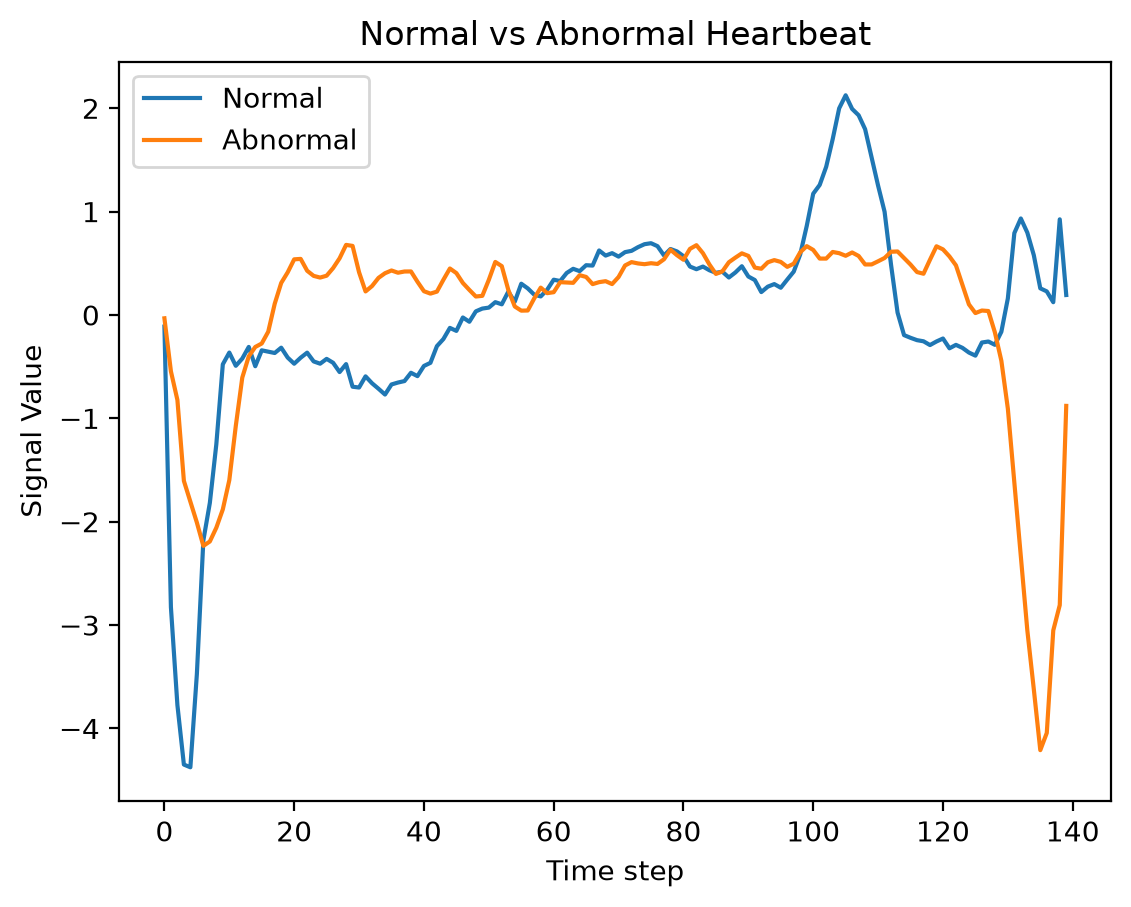

In [7]:
X_train[y_train == 1][0]
plt.plot(X_train[y_train == 1][0], label="Normal")
plt.plot(X_train[y_train == 2][0], label="Abnormal")
plt.title("Normal vs Abnormal Heartbeat")
plt.legend()
plt.xlabel("Time step")
plt.ylabel("Signal Value")
plt.show()

In [8]:
y_train = (y_train != 1).astype(int)
y_test = (y_test != 1).astype(int)

In [9]:
print(np.unique(y_train, return_counts=True))          # labels 1-5
print(np.unique(y_test, return_counts=True))      # only 0 and 1

(array([0, 1]), array([292, 208]))
(array([0, 1]), array([2627, 1873]))


In [10]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [11]:
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
X_train.shape

(500, 140)

In [13]:
X_train = X_train.reshape(-1, 140, 1) # -1 is np choses total samples in file 140 is timestamps 1 is the output
X_test = X_test.reshape(-1, 140, 1)

In [14]:
print(np.unique(y_train))
print(np.unique(y_test))

[0 1]
[0 1]


In [15]:
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("logs", exist_ok=True)
os.makedirs("checkpoints/plain_lstm", exist_ok=True)

In [16]:
callbacks = [
    EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1
    ),
    ModelCheckpoint(
        "checkpoints/plain_lstm/best_model.keras",
        monitor="val_loss", save_best_only=True, verbose=1
    ),
    TensorBoard(log_dir="logs/plain_lstm_run1"),
]

In [17]:
model = Sequential()
model.add(Input(shape=(140, 1)))
model.add(LSTM(64))
model.add(Dropout(0.3))
model.add(Dense(1, activation="sigmoid"))
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

2026-10-18 22:18:49.058464: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-18 22:18:49.058491: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-10-18 22:18:49.058495: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-10-18 22:18:49.058512: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-18 22:18:49.058523: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(X_train, y_train, validation_split=0.15, callbacks=callbacks, epochs=100)

Epoch 1/100


2026-10-18 22:18:49.520213: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9082 - loss: 0.5883
Epoch 1: val_loss improved from None to 0.56605, saving model to checkpoints/plain_lstm/best_model.keras

Epoch 1: finished saving model to checkpoints/plain_lstm/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.9082 - loss: 0.5883 - val_accuracy: 0.8667 - val_loss: 0.5660 - learning_rate: 0.0010
Epoch 2/100
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9567 - loss: 0.3734
Epoch 2: val_loss improved from 0.56605 to 0.51855, saving model to checkpoints/plain_lstm/best_model.keras

Epoch 2: finished saving model to checkpoints/plain_lstm/best_model.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9553 - loss: 0.3712 - val_accuracy: 0.8667 - val_loss: 0.5185 - learning_rate: 0.0010
Epoch 3/100
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9808 - loss: 0.1516
Epoch 3: val_loss improved from 0.51855 to 0.43204, saving model to checkpoints/plain_lstm/best_model.keras

Ep

In [20]:
y_prob = model.predict(X_test)
y_prob = y_prob.flatten()
y_pred = (y_prob > 0.5).astype(int)

y_train_prob = model.predict(X_train).flatten()
y_train_pred = (y_train_prob > 0.5).astype(int)

141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [21]:
print("Training")
print(f"Accuracy Score: {accuracy_score(y_train, y_train_pred)}")
print(f"Recall: {recall_score(y_train, y_train_pred)}")
print(f"Precision: {precision_score(y_train, y_train_pred)}")
print(f"F1: {f1_score(y_train, y_train_pred)}")
print(f"ROC-AUC: {roc_auc_score(y_train, y_train_prob)}")
print(f"Confusion Matrix: \n{confusion_matrix(y_train, y_train_pred)}")
print(f"Classification Report: \n{classification_report(y_train, y_train_pred)}")
print("Testing")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")
print(f"Precision: {precision_score(y_test, y_pred)}")
print(f"F1: {f1_score(y_test, y_pred)}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob)}")
print(f"Confusion matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report: \n{classification_report(y_test, y_pred)}")

Training
Accuracy Score: 0.974
Recall: 0.9375
Precision: 1.0
F1: 0.967741935483871
ROC-AUC: 0.9992261591148577
Confusion Matrix: 
[[292   0]
 [ 13 195]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       292
           1       1.00      0.94      0.97       208

    accuracy                           0.97       500
   macro avg       0.98      0.97      0.97       500
weighted avg       0.98      0.97      0.97       500

Testing
Accuracy Score: 0.9622222222222222
Recall: 0.9119060331019755
Precision: 0.997081144191477
F1: 0.9525934188510876
ROC-AUC: 0.9956663836934248
Confusion matrix: 
[[2622    5]
 [ 165 1708]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      2627
           1       1.00      0.91      0.95      1873

    accuracy                           0.96      4500
   macro avg       0.97      0.96      0.96      4500
weig

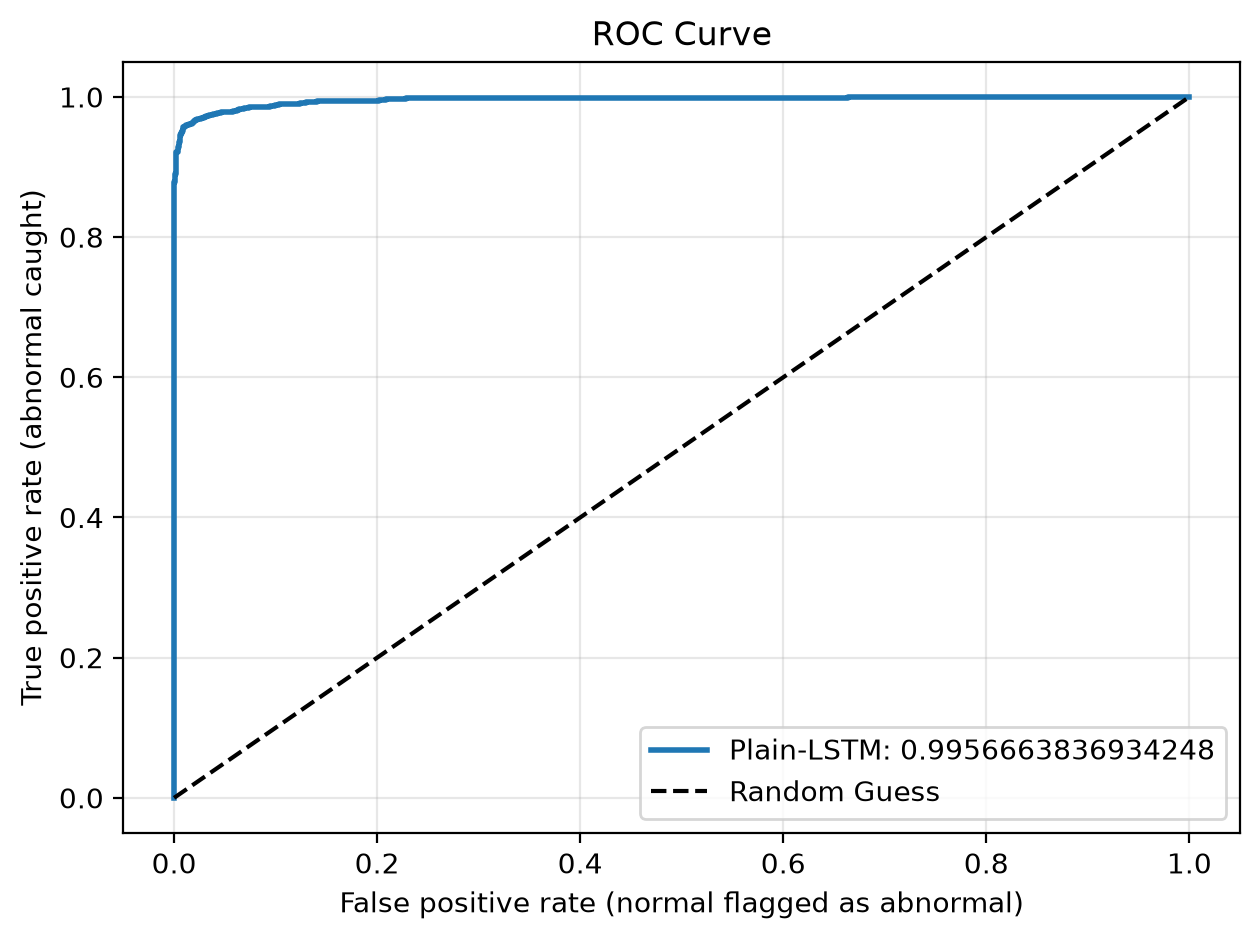

In [22]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, linewidth=2, label=f"Plain-LSTM: {roc_auc_score(y_test, y_prob)}")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False positive rate (normal flagged as abnormal)")
plt.ylabel("True positive rate (abnormal caught)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/roc_auc_curve_plain_lstm.png")
plt.show()

In [23]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


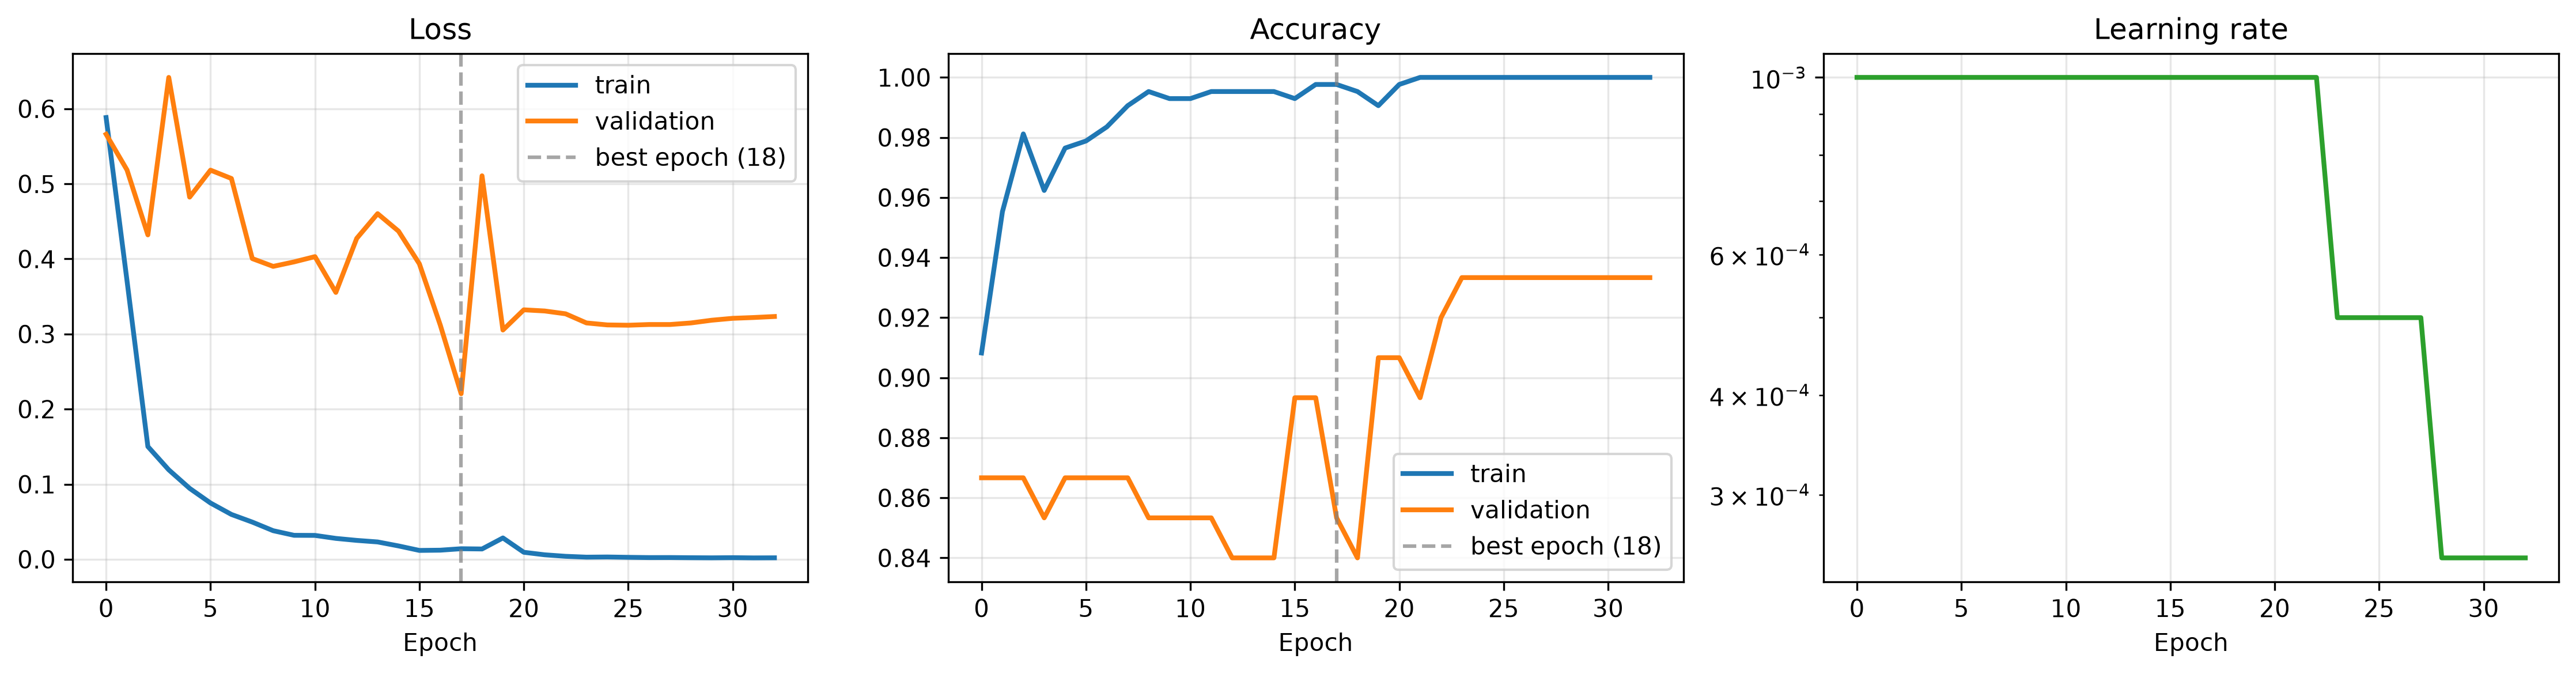

In [24]:
import matplotlib.pyplot as plt
import numpy as np

def plot_history(history):
    h = history.history
    best_epoch = int(np.argmin(h["val_loss"]))
    panels = [("loss", "Loss"), ("accuracy", "Accuracy")]
    panels = [(k, t) for k, t in panels if k in h]

    lr_key = next((k for k in ("learning_rate", "lr") if k in h), None)
    n = len(panels) + (1 if lr_key else 0)

    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), dpi=150)
    axes = np.atleast_1d(axes)

    for ax, (key, title) in zip(axes, panels):
        ax.plot(h[key], label="train", linewidth=2)
        ax.plot(h[f"val_{key}"], label="validation", linewidth=2)
        ax.axvline(best_epoch, color="gray", linestyle="--", alpha=0.7,
                   label=f"best epoch ({best_epoch + 1})")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()

    if lr_key:
        ax = axes[-1]
        ax.plot(h[lr_key], color="tab:green", linewidth=2)
        ax.set_yscale("log")
        ax.set_title("Learning rate")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig("images/training_curves_plain_lstm.png")
    plt.show()

plot_history(history)

In [25]:
os.makedirs("scaler", exist_ok=True)
joblib.dump(scaler, "scaler/scaler_plain_lstm.pkl")

['scaler/scaler_plain_lstm.pkl']